In [17]:
# ============================================================
# ALL IMPORTS
# ============================================================
import torch
import torch.nn.functional as F
import torch.nn as nn
from torch_geometric.nn import GATConv, GCNConv
from torch_geometric.data import Data
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import numpy as np
import copy, time, os
import warnings
warnings.filterwarnings('ignore')

# Load graph
data = torch.load('outputs/ibm_graph.pt', weights_only=False)
device = torch.device('cpu')

print("✅ Everything loaded!")
print(f"Nodes:     {data.num_nodes:,}")
print(f"Edges:     {data.num_edges:,}")
print(f"Features:  {data.num_node_features}")
print(f"Fraud:     {data.y.sum().item():,}")
print(f"Legit:     {(data.y==0).sum().item():,}")

✅ Everything loaded!
Nodes:     515,088
Edges:     5,078,345
Features:  13
Fraud:     6,357
Legit:     508,731


In [18]:
torch.manual_seed(42)
np.random.seed(42)

# Stratified sampling — fraud zaroor include hoga
TRAIN_FRAUD = 1500
TRAIN_LEGIT = 4500
VAL_FRAUD   = 500
VAL_LEGIT   = 1500
TEST_FRAUD  = 500
TEST_LEGIT  = 1500

train_idx = torch.where(data.train_mask)[0]
val_idx   = torch.where(data.val_mask)[0]
test_idx  = torch.where(data.test_mask)[0]

train_fraud = train_idx[data.y[train_idx] == 1]
train_legit = train_idx[data.y[train_idx] == 0]
val_fraud   = val_idx[data.y[val_idx] == 1]
val_legit   = val_idx[data.y[val_idx] == 0]
test_fraud  = test_idx[data.y[test_idx] == 1]
test_legit  = test_idx[data.y[test_idx] == 0]

print("Available nodes:")
print(f"  Train — Fraud: {len(train_fraud):,}  Legit: {len(train_legit):,}")
print(f"  Val   — Fraud: {len(val_fraud):,}  Legit: {len(val_legit):,}")
print(f"  Test  — Fraud: {len(test_fraud):,}  Legit: {len(test_legit):,}")

def sample_nodes(fraud_nodes, legit_nodes, n_fraud, n_legit):
    n_fraud = min(n_fraud, len(fraud_nodes))
    n_legit = min(n_legit, len(legit_nodes))
    fraud_s = fraud_nodes[torch.randperm(len(fraud_nodes))[:n_fraud]]
    legit_s = legit_nodes[torch.randperm(len(legit_nodes))[:n_legit]]
    return torch.cat([fraud_s, legit_s])

selected_train = sample_nodes(train_fraud, train_legit, TRAIN_FRAUD, TRAIN_LEGIT)
selected_val   = sample_nodes(val_fraud,   val_legit,   VAL_FRAUD,   VAL_LEGIT)
selected_test  = sample_nodes(test_fraud,  test_legit,  TEST_FRAUD,  TEST_LEGIT)
selected_nodes = torch.unique(torch.cat([selected_train, selected_val, selected_test]))

# Build subgraph
old_to_new = torch.full((data.num_nodes,), -1, dtype=torch.long)
old_to_new[selected_nodes] = torch.arange(len(selected_nodes))

src, dst  = data.edge_index[0], data.edge_index[1]
edge_mask = (old_to_new[src] >= 0) & (old_to_new[dst] >= 0)
new_edge_index = torch.stack([old_to_new[src[edge_mask]],
                               old_to_new[dst[edge_mask]]], dim=0)

sub_data = Data(
    x          = data.x[selected_nodes],
    y          = data.y[selected_nodes],
    edge_index = new_edge_index
)
if hasattr(data, 'edge_attr') and data.edge_attr is not None:
    sub_data.edge_attr = data.edge_attr[edge_mask]

# Masks
sub_data.train_mask = torch.zeros(len(selected_nodes), dtype=torch.bool)
sub_data.val_mask   = torch.zeros(len(selected_nodes), dtype=torch.bool)
sub_data.test_mask  = torch.zeros(len(selected_nodes), dtype=torch.bool)
sub_data.train_mask[old_to_new[selected_train]] = True
sub_data.val_mask[old_to_new[selected_val]]     = True
sub_data.test_mask[old_to_new[selected_test]]   = True

sub_data = sub_data.to(device)

print(f"\n✅ Stratified Subgraph created!")
print(f"Nodes:        {sub_data.num_nodes:,}")
print(f"Edges:        {sub_data.edge_index.shape[1]:,}")
print(f"Train nodes:  {sub_data.train_mask.sum().item():,}")
print(f"Val nodes:    {sub_data.val_mask.sum().item():,}")
print(f"Test nodes:   {sub_data.test_mask.sum().item():,}")
print(f"Fraud total:  {(sub_data.y==1).sum().item():,}")

Available nodes:
  Train — Fraud: 4,450  Legit: 356,111
  Val   — Fraud: 951  Legit: 76,312
  Test  — Fraud: 956  Legit: 76,308

✅ Stratified Subgraph created!
Nodes:        10,000
Edges:        21,741
Train nodes:  6,000
Val nodes:    2,000
Test nodes:   2,000
Fraud total:  2,500


In [19]:
class FraudGAT(nn.Module):
    def __init__(self, in_channels, hidden=64, out=2, heads=4, dropout=0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden, heads=heads, dropout=dropout)
        self.gat2 = GATConv(hidden*heads, hidden, heads=2, dropout=dropout)
        self.gat3 = GATConv(hidden*2, out, heads=1, concat=False, dropout=dropout)
        self.drop = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.elu(self.gat1(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.elu(self.gat2(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        return self.gat3(x, edge_index)

model = FraudGAT(
    in_channels = sub_data.num_node_features,
    hidden=64, out=2, heads=4, dropout=0.3
).to(device)

print("✅ GAT Model created!")
print(model)
print(f"\nFeatures:   {sub_data.num_node_features}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

✅ GAT Model created!
FraudGAT(
  (gat1): GATConv(13, 64, heads=4)
  (gat2): GATConv(256, 64, heads=2)
  (gat3): GATConv(128, 2, heads=1)
)

Features:   13
Parameters: 37,510


In [20]:
# Class weights
train_labels  = sub_data.y[sub_data.train_mask]
class_counts  = torch.bincount(train_labels, minlength=2).float()
class_weights = (class_counts.sum() / (2.0 * class_counts)).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=5
)

print(f"Fraud weight:  {class_weights[1]:.4f}")
print(f"Legit weight:  {class_weights[0]:.4f}")
print("✅ Training setup ready!")

Fraud weight:  2.0000
Legit weight:  0.6667
✅ Training setup ready!


In [21]:
NUM_EPOCHS = 150
PATIENCE   = 15

best_val_auc   = 0.0
best_epoch     = 0
patience_count = 0
best_state     = None
train_losses   = []
val_aucs       = []

print("Epoch | Loss   | Val AUC | PR-AUC | Recall | LR")
print("-"*60)

for epoch in range(1, NUM_EPOCHS+1):
    model.train()
    optimizer.zero_grad()
    out  = model(sub_data.x, sub_data.edge_index)
    loss = criterion(out[sub_data.train_mask], sub_data.y[sub_data.train_mask])
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_out  = model(sub_data.x, sub_data.edge_index)
        val_prob = F.softmax(val_out[sub_data.val_mask], dim=1)[:,1].cpu().numpy()
        val_true = sub_data.y[sub_data.val_mask].cpu().numpy()

    val_auc    = roc_auc_score(val_true, val_prob)
    val_prauc  = average_precision_score(val_true, val_prob)
    val_pred   = (val_prob >= 0.5).astype(int)
    val_recall = recall_score(val_true, val_pred, zero_division=0)

    scheduler.step(val_auc)
    train_losses.append(loss.item())
    val_aucs.append(val_auc)

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        best_epoch   = epoch
        best_state   = copy.deepcopy(model.state_dict())
        patience_count = 0
    else:
        patience_count += 1

    if epoch % 10 == 0 or epoch == 1:
        lr = optimizer.param_groups[0]['lr']
        print(f"  {epoch:3d} | {loss.item():.4f} | {val_auc:.4f}  | {val_prauc:.4f} | {val_recall:.4f} | {lr:.5f}")

    if patience_count >= PATIENCE:
        print(f"\n⏹️ Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print(f"\n✅ Training complete!")
print(f"Best epoch:    {best_epoch}")
print(f"Best Val AUC:  {best_val_auc:.4f}")

# Save model
os.makedirs('outputs', exist_ok=True)
torch.save(model.state_dict(), 'outputs/fraud_gat_model.pt')
print("✅ Model saved!")

Epoch | Loss   | Val AUC | PR-AUC | Recall | LR
------------------------------------------------------------
    1 | 1.8147 | 0.6545  | 0.3721 | 0.5880 | 0.00100
   10 | 1.7273 | 0.7254  | 0.4302 | 0.6300 | 0.00100
   20 | 0.7375 | 0.7178  | 0.4377 | 0.6440 | 0.00050

⏹️ Early stopping at epoch 26

✅ Training complete!
Best epoch:    11
Best Val AUC:  0.7315
✅ Model saved!


In [22]:
model.eval()
with torch.no_grad():
    test_out  = model(sub_data.x, sub_data.edge_index)
    test_prob = F.softmax(test_out[sub_data.test_mask], dim=1)[:,1].cpu().numpy()
    test_true = sub_data.y[sub_data.test_mask].cpu().numpy()

test_pred = (test_prob >= 0.5).astype(int)
gat_auc   = roc_auc_score(test_true, test_prob)
gat_prauc = average_precision_score(test_true, test_prob)
gat_rec   = recall_score(test_true, test_pred, zero_division=0)
gat_prec  = precision_score(test_true, test_pred, zero_division=0)
gat_f1    = f1_score(test_true, test_pred, zero_division=0)
gat_cm    = confusion_matrix(test_true, test_pred)

print("="*55)
print("  GAT FINAL TEST RESULTS")
print("="*55)
print(classification_report(test_true, test_pred,
      target_names=['Legit','Fraud']))
print(f"ROC-AUC:  {gat_auc:.4f}")
print(f"PR-AUC:   {gat_prauc:.4f}")
print(f"\nConfusion Matrix:")
print(gat_cm)

  GAT FINAL TEST RESULTS
              precision    recall  f1-score   support

       Legit       0.85      0.67      0.75      1500
       Fraud       0.40      0.66      0.49       500

    accuracy                           0.67      2000
   macro avg       0.63      0.66      0.62      2000
weighted avg       0.74      0.67      0.69      2000

ROC-AUC:  0.7675
PR-AUC:   0.4429

Confusion Matrix:
[[1002  498]
 [ 172  328]]


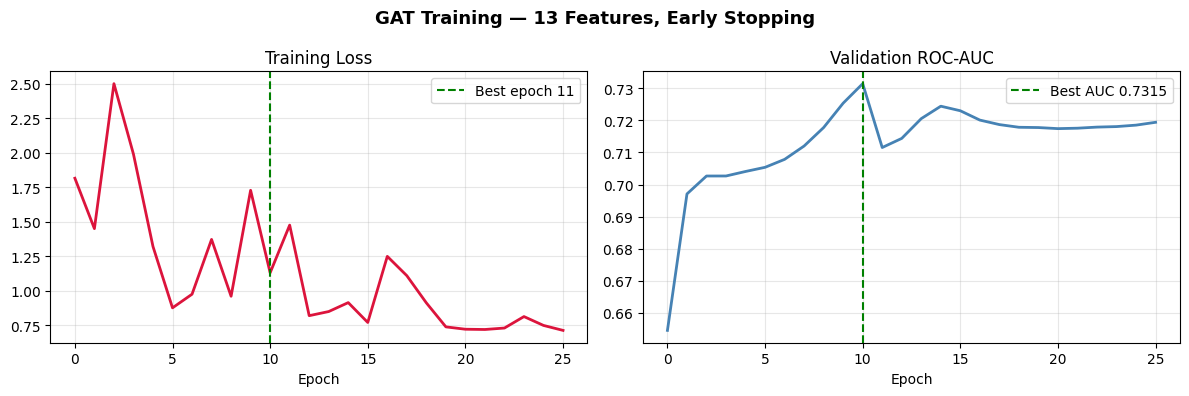

✅ Training curves saved!


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('GAT Training — 13 Features, Early Stopping', fontsize=13, fontweight='bold')

axes[0].plot(train_losses, color='crimson', linewidth=2)
axes[0].axvline(best_epoch-1, color='green', linestyle='--', label=f'Best epoch {best_epoch}')
axes[0].set_title('Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(val_aucs, color='steelblue', linewidth=2)
axes[1].axvline(best_epoch-1, color='green', linestyle='--', label=f'Best AUC {best_val_auc:.4f}')
axes[1].set_title('Validation ROC-AUC')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training curves saved!")

In [24]:
class FraudGCN(nn.Module):
    def __init__(self, in_channels, hidden=32, out=2, dropout=0.3):
        super().__init__()
        self.gcn1 = GCNConv(in_channels, hidden)
        self.gcn2 = GCNConv(hidden, hidden)
        self.gcn3 = GCNConv(hidden, out)
        self.drop = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.relu(self.gcn1(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.relu(self.gcn2(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        return self.gcn3(x, edge_index)

gcn = FraudGCN(sub_data.num_node_features).to(device)
gcn_weights   = (class_counts.sum() / (2.0*class_counts)).to(device)
gcn_criterion = nn.CrossEntropyLoss(weight=gcn_weights)
gcn_optimizer = torch.optim.Adam(gcn.parameters(), lr=0.001, weight_decay=1e-4)
gcn_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    gcn_optimizer, mode='max', factor=0.5, patience=5
)

best_gcn_auc, best_gcn_state, gcn_patience = 0.0, None, 0

print("Training GCN...")
for epoch in range(1, 151):
    gcn.train()
    gcn_optimizer.zero_grad()
    out  = gcn(sub_data.x, sub_data.edge_index)
    loss = gcn_criterion(out[sub_data.train_mask], sub_data.y[sub_data.train_mask])
    loss.backward()
    torch.nn.utils.clip_grad_norm_(gcn.parameters(), 2.0)
    gcn_optimizer.step()

    gcn.eval()
    with torch.no_grad():
        vp = F.softmax(gcn(sub_data.x, sub_data.edge_index)[sub_data.val_mask], dim=1)[:,1].numpy()
        vt = sub_data.y[sub_data.val_mask].numpy()
    vauc = roc_auc_score(vt, vp)
    gcn_scheduler.step(vauc)

    if vauc > best_gcn_auc:
        best_gcn_auc   = vauc
        best_gcn_state = copy.deepcopy(gcn.state_dict())
        gcn_patience   = 0
    else:
        gcn_patience += 1
    if gcn_patience >= 15:
        print(f"Early stopping at epoch {epoch}")
        break
    if epoch % 20 == 0:
        print(f"  Epoch {epoch} | Loss: {loss.item():.4f} | Val AUC: {vauc:.4f}")

gcn.load_state_dict(best_gcn_state)
gcn.eval()
with torch.no_grad():
    tp = F.softmax(gcn(sub_data.x, sub_data.edge_index)[sub_data.test_mask], dim=1)[:,1].numpy()
    tt = sub_data.y[sub_data.test_mask].numpy()

gcn_auc   = roc_auc_score(tt, tp)
gcn_prauc = average_precision_score(tt, tp)
gcn_pred  = (tp >= 0.5).astype(int)
gcn_rec   = recall_score(tt, gcn_pred, zero_division=0)
gcn_prec  = precision_score(tt, gcn_pred, zero_division=0)
gcn_f1    = f1_score(tt, gcn_pred, zero_division=0)
gcn_cm    = confusion_matrix(tt, gcn_pred)

print(f"\n✅ GCN Results:")
print(f"ROC-AUC: {gcn_auc:.4f} | PR-AUC: {gcn_prauc:.4f} | Recall: {gcn_rec:.4f}")

Training GCN...
  Epoch 20 | Loss: 1.0713 | Val AUC: 0.5034
Early stopping at epoch 28

✅ GCN Results:
ROC-AUC: 0.5613 | PR-AUC: 0.3062 | Recall: 0.3060


In [25]:
X = sub_data.x.cpu().numpy()
y_np = sub_data.y.cpu().numpy()

X_train = X[sub_data.train_mask.cpu().numpy()]
y_train = y_np[sub_data.train_mask.cpu().numpy()]
X_val   = X[sub_data.val_mask.cpu().numpy()]
y_val   = y_np[sub_data.val_mask.cpu().numpy()]
X_test  = X[sub_data.test_mask.cpu().numpy()]
y_test_rf = y_np[sub_data.test_mask.cpu().numpy()]

# SMOTE apply karo
print("Applying SMOTE...")
sm = SMOTE(random_state=42, k_neighbors=3)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)
print(f"Before SMOTE — Fraud: {(y_train==1).sum()}, Legit: {(y_train==0).sum()}")
print(f"After SMOTE  — Fraud: {(y_train_sm==1).sum()}, Legit: {(y_train_sm==0).sum()}")

# Random Forest
rf = RandomForestClassifier(
    n_estimators=200, max_depth=12,
    class_weight='balanced', random_state=42, n_jobs=-1
)
print("\nTraining Random Forest + SMOTE...")
rf.fit(X_train_sm, y_train_sm)

rf_prob  = rf.predict_proba(X_test)[:,1]
rf_pred  = (rf_prob >= 0.5).astype(int)
rf_auc   = roc_auc_score(y_test_rf, rf_prob)
rf_prauc = average_precision_score(y_test_rf, rf_prob)
rf_rec   = recall_score(y_test_rf, rf_pred, zero_division=0)
rf_prec  = precision_score(y_test_rf, rf_pred, zero_division=0)
rf_f1    = f1_score(y_test_rf, rf_pred, zero_division=0)
rf_cm    = confusion_matrix(y_test_rf, rf_pred)

print(f"\n✅ Random Forest + SMOTE Results:")
print(f"ROC-AUC: {rf_auc:.4f} | PR-AUC: {rf_prauc:.4f} | Recall: {rf_rec:.4f}")

Applying SMOTE...
Before SMOTE — Fraud: 1500, Legit: 4500
After SMOTE  — Fraud: 4500, Legit: 4500

Training Random Forest + SMOTE...

✅ Random Forest + SMOTE Results:
ROC-AUC: 0.8657 | PR-AUC: 0.6350 | Recall: 0.7660


In [26]:
class FraudMLP(nn.Module):
    def __init__(self, in_f, h1=64, h2=32, drop=0.3):
        super().__init__()
        self.fc1  = nn.Linear(in_f, h1)
        self.fc2  = nn.Linear(h1, h2)
        self.fc3  = nn.Linear(h2, 2)
        self.drop = drop
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.relu(self.fc2(x))
        x = F.dropout(x, p=self.drop, training=self.training)
        return self.fc3(x)

mlp = FraudMLP(sub_data.num_node_features).to(device)

# SMOTE data as tensors
X_sm_t = torch.tensor(X_train_sm, dtype=torch.float).to(device)
y_sm_t = torch.tensor(y_train_sm, dtype=torch.long).to(device)
X_val_t = torch.tensor(X_val, dtype=torch.float).to(device)
X_test_t = torch.tensor(X_test, dtype=torch.float).to(device)

mlp_counts = torch.bincount(y_sm_t, minlength=2).float()
mlp_w = (mlp_counts.sum() / (2*mlp_counts)).to(device)
mlp_crit = nn.CrossEntropyLoss(weight=mlp_w)
mlp_opt  = torch.optim.Adam(mlp.parameters(), lr=0.001, weight_decay=1e-4)

best_mlp_auc, best_mlp_state, mlp_patience = 0.0, None, 0

print("Training MLP + SMOTE...")
for epoch in range(1, 151):
    mlp.train()
    mlp_opt.zero_grad()
    out  = mlp(X_sm_t)
    loss = mlp_crit(out, y_sm_t)
    loss.backward()
    mlp_opt.step()

    mlp.eval()
    with torch.no_grad():
        vp = F.softmax(mlp(X_val_t), dim=1)[:,1].cpu().numpy()
    vauc = roc_auc_score(y_val, vp)

    if vauc > best_mlp_auc:
        best_mlp_auc   = vauc
        best_mlp_state = copy.deepcopy(mlp.state_dict())
        mlp_patience   = 0
    else:
        mlp_patience += 1
    if mlp_patience >= 15:
        print(f"Early stopping at epoch {epoch}")
        break
    if epoch % 20 == 0:
        print(f"  Epoch {epoch} | Loss: {loss.item():.4f} | Val AUC: {vauc:.4f}")

mlp.load_state_dict(best_mlp_state)
mlp.eval()
with torch.no_grad():
    mlp_prob = F.softmax(mlp(X_test_t), dim=1)[:,1].cpu().numpy()

mlp_pred  = (mlp_prob >= 0.5).astype(int)
mlp_auc   = roc_auc_score(y_test_rf, mlp_prob)
mlp_prauc = average_precision_score(y_test_rf, mlp_prob)
mlp_rec   = recall_score(y_test_rf, mlp_pred, zero_division=0)
mlp_prec  = precision_score(y_test_rf, mlp_pred, zero_division=0)
mlp_f1    = f1_score(y_test_rf, mlp_pred, zero_division=0)
mlp_cm    = confusion_matrix(y_test_rf, mlp_pred)

print(f"\n✅ MLP + SMOTE Results:")
print(f"ROC-AUC: {mlp_auc:.4f} | PR-AUC: {mlp_prauc:.4f} | Recall: {mlp_rec:.4f}")

Training MLP + SMOTE...
  Epoch 20 | Loss: 0.6396 | Val AUC: 0.6843
  Epoch 40 | Loss: 0.6129 | Val AUC: 0.6974
  Epoch 60 | Loss: 0.5907 | Val AUC: 0.7401
  Epoch 80 | Loss: 0.5802 | Val AUC: 0.7692
  Epoch 100 | Loss: 0.5652 | Val AUC: 0.7769
  Epoch 120 | Loss: 0.5560 | Val AUC: 0.7829
  Epoch 140 | Loss: 0.5434 | Val AUC: 0.7893

✅ MLP + SMOTE Results:
ROC-AUC: 0.8159 | PR-AUC: 0.5440 | Recall: 0.8000



   FINAL MODEL COMPARISON
Model                  ROC-AUC   PR-AUC  Precision   Recall      F1
----------------------------------------------------------------------
GAT (Ours)             0.7675   0.4429     0.3971   0.6560  0.4947 ← GNN
GCN                    0.5613   0.3062     0.3006   0.3060  0.3033
RF + SMOTE             0.8657   0.6350     0.5543   0.7660  0.6432
MLP + SMOTE            0.8159   0.5440     0.4556   0.8000  0.5806

Best ROC-AUC: RF + SMOTE
Best Recall:  MLP + SMOTE


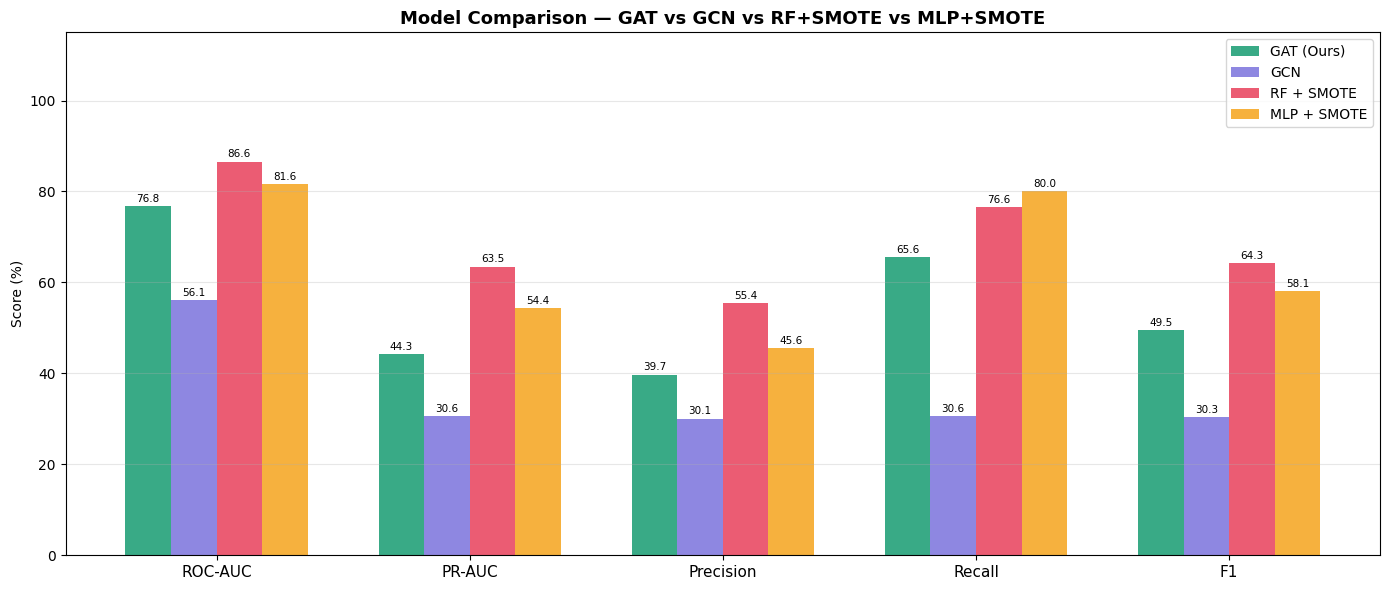

✅ Comparison chart saved!


In [27]:
print("\n" + "="*70)
print("   FINAL MODEL COMPARISON")
print("="*70)
print(f"{'Model':<20} {'ROC-AUC':>9} {'PR-AUC':>8} {'Precision':>10} {'Recall':>8} {'F1':>7}")
print("-"*70)

results = {
    'GAT (Ours)':    [gat_auc,  gat_prauc,  gat_prec,  gat_rec,  gat_f1],
    'GCN':           [gcn_auc,  gcn_prauc,  gcn_prec,  gcn_rec,  gcn_f1],
    'RF + SMOTE':    [rf_auc,   rf_prauc,   rf_prec,   rf_rec,   rf_f1],
    'MLP + SMOTE':   [mlp_auc,  mlp_prauc,  mlp_prec,  mlp_rec,  mlp_f1],
}

for name, vals in results.items():
    marker = " ← GNN" if 'GAT' in name else ""
    print(f"{name:<20} {vals[0]:>8.4f} {vals[1]:>8.4f} {vals[2]:>10.4f} {vals[3]:>8.4f} {vals[4]:>7.4f}{marker}")

print("="*70)
best_auc_model = max(results, key=lambda k: results[k][0])
best_rec_model = max(results, key=lambda k: results[k][3])
print(f"\nBest ROC-AUC: {best_auc_model}")
print(f"Best Recall:  {best_rec_model}")

# Bar chart
metrics   = ['ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1']
colors    = ['#1D9E75', '#7F77DD', '#E94560', '#F5A623']
x         = np.arange(len(metrics))
w         = 0.18

fig, ax = plt.subplots(figsize=(14, 6))
for i, (name, vals) in enumerate(results.items()):
    bars = ax.bar(x + i*w, [v*100 for v in vals], w,
                  label=name, color=colors[i], alpha=0.88)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.5,
                f'{val*100:.1f}', ha='center', va='bottom', fontsize=7.5)

ax.set_xticks(x + w*1.5)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 115)
ax.set_title('Model Comparison — GAT vs GCN vs RF+SMOTE vs MLP+SMOTE',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Comparison chart saved!")

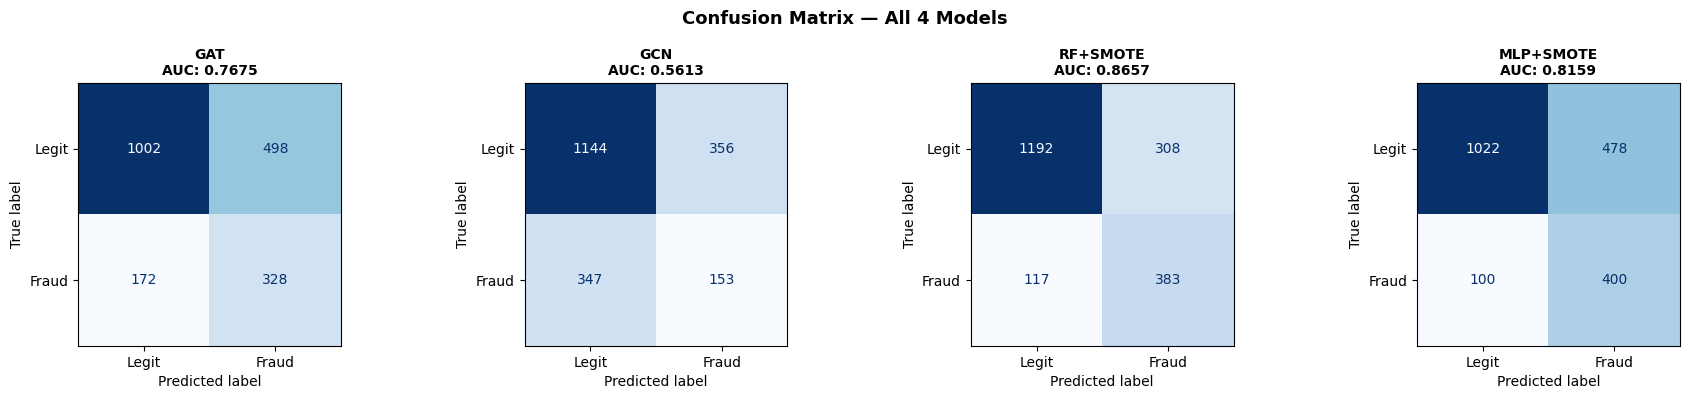

✅ All confusion matrices saved!


In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle('Confusion Matrix — All 4 Models', fontsize=13, fontweight='bold')

all_cms   = [gat_cm,    gcn_cm,    rf_cm,     mlp_cm]
all_names = ['GAT','GCN','RF+SMOTE','MLP+SMOTE']
all_cols  = ['#1D9E75','#7F77DD','#E94560','#F5A623']

from sklearn.metrics import ConfusionMatrixDisplay
for ax, cm, name in zip(axes, all_cms, all_names):
    ConfusionMatrixDisplay(cm, display_labels=['Legit','Fraud'])\
        .plot(ax=ax, colorbar=False, cmap='Blues')
    auc = results[name.replace('+SMOTE','').strip()+(' + SMOTE' if 'SMOTE' in name else '')
                  if name+'  ' in str(results) else list(results.keys())[all_names.index(name)]
                 ][0] if name in [n.replace(' (Ours)','') for n in results] else 0
    ax.set_title(f"{name}\nAUC: {results[list(results.keys())[all_names.index(name)]][0]:.4f}",
                 fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('outputs/all_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ All confusion matrices saved!")